In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [4]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH +"final_df.parquet"

final_df = pd.read_parquet(DATA_PATH)

parent_node = pd.read_csv(ROOT_PATH + "parent_node.csv")

all_mut_data = pd.read_parquet(ROOT_PATH +'all_nodes_spike_2025-09-01_branch.parquet') 

dates_df = pd.read_csv(ROOT_PATH + 'chronumental_dates_gisaidAndPublic.2025-09-01.metadata.tsv', sep='\t')

ver = 'Jan_4_24'
pyro_df = pd.read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

In [5]:
# --- Preprocess Date Data ---
dates_df['predicted_date'] = pd.to_datetime(dates_df['predicted_date'])

dates_df['predicted_date'] = dates_df['predicted_date'].dt.date

dates_df['predicted_date'] = pd.to_datetime(dates_df['predicted_date'])

dates_df = dates_df.rename(columns={'strain': 'node_id'})

In [6]:
# --- Define cutoff date ---
cutoff_date = "2022-07-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']

# --- Perform slicing ---
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Combine slices into one dictionary ---
future_slices = disjoint_slices

# --- Summary output ---
# print(f"Cumulative slices: {list(cumulative_slices.keys())}")
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['3M_1', '3M_2', '3M_3', '3M_4']
Total future slices stored: 4


Processing Nodes around Cutoff Date

In [7]:
# --- Filter Nodes around cutoff date ---
filtered_df = dates_df[dates_df['predicted_date'] < cutoff_date]


filtered_df = filtered_df[filtered_df['node_id'].str.contains('node_')]


nodes_before_cutoff = set(filtered_df['node_id'])

In [9]:
# --- Create Lookup Dictionaries ---
parent_node_clean = parent_node.dropna().drop_duplicates(subset=["node"])

parent_lookup = dict(zip(parent_node_clean["node"], parent_node_clean["parent_node"]))

mutations_lookup = dict(zip(all_mut_data['sample_id'], all_mut_data['aa_mutations']))

fitness_lookup = dict(zip(pyro_df['mutation'], pyro_df['R / R_A']))

In [10]:
# --- Apply functions to future data ---
for key, df in future_slices.items():
    df = df.copy()

    # Existing computations
    df["node_path"] = df["Sample_ID"].apply(lambda x: build_node_path(x, parent_lookup))
    df["anchor_remainder"] = df["node_path"].apply(
        lambda path: find_anchor_remainder_reverse(path, nodes_before_cutoff)
    )
    remainder_muts = df["anchor_remainder"].apply(
        lambda ar: get_mutations_from_remainder(ar, mutations_lookup)
    )
    df["mutations_in_remainder"] = remainder_muts
    df["total_mutations_in_remainder"] = remainder_muts.str.len()

    future_slices[key] = df

In [11]:
def get_fitness_list(mutation_list):
        return [fitness_lookup.get(mut, 1) for mut in mutation_list] # PyR0 default fitness is 1

for key, df in future_slices.items():
    df['fitness_in_remainder'] = df['mutations_in_remainder'].apply(get_fitness_list)
    future_slices[key] = df

In [12]:
slice_stats = {}

for key, df in future_slices.items():

    all_mutations = [m for lst in df['mutations_in_remainder'] for m in lst]
    
    slice_stats[key] = {
        "total_mutations": len(all_mutations),
        "unique_mutations": len(set(all_mutations)),
        "total_tips": len(df)  
    }

Process Mutation Counts

In [13]:
# --- Compute fitness frequency distributions ---
fitness_freqs = {}

for key, df in future_slices.items():
    # Flatten all fitness scores across tips seen after the cutoff
    all_fitness = [f for lst in df['fitness_in_remainder'] for f in lst if f is not None]
    
    # Count frequency of each score
    freq_df = pd.Series(all_fitness).value_counts().reset_index()
    freq_df.columns = ["fitness_score", "frequency"]
    
    # Store in dict
    fitness_freqs[key] = freq_df

fitness_freqs_normalized = {}

for key, freq_df in fitness_freqs.items():
    total_tips = slice_stats[key]["total_mutations"]

    # add a normalized percentage column
    freq_df = freq_df.copy()
    freq_df["percent"] = (freq_df["frequency"] / total_tips) * 100

    fitness_freqs_normalized[key] = freq_df

In [14]:
import numpy as np

bin_edges = np.arange(0.85, 1.19 + 0.01, 0.01)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

binned_results = {}

for key, df in fitness_freqs_normalized.items():
    # sum percent in each bin
    binned, _ = np.histogram(
        df["fitness_score"],
        bins=bin_edges,
        weights=df["percent"]  # sum of percentages
    )

    binned_results[key] = pd.DataFrame({
        "bin_center": bin_centers,
        "percent_sum": binned
    })

Plot Results

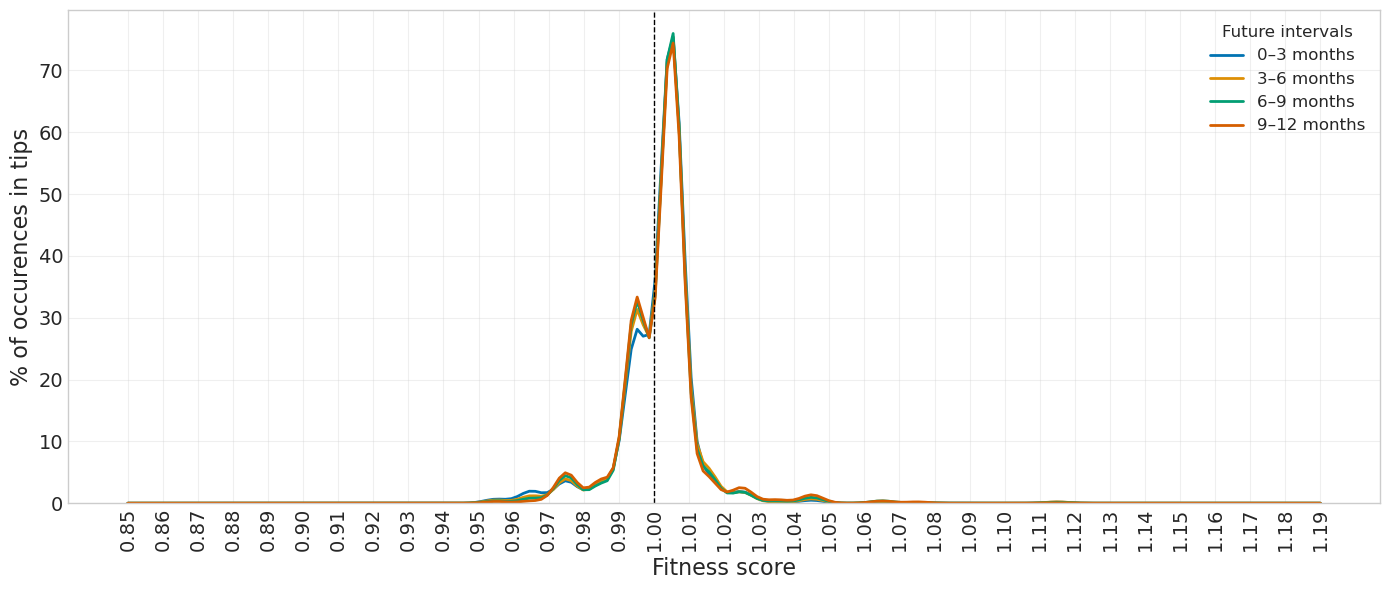

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


slices_to_plot = ["3M_1", "3M_2", "3M_3", "3M_4"]  # fixed order
legend_labels = {
    "3M_1": "0–3 months",
    "3M_2": "3–6 months",
    "3M_3": "6–9 months",
    "3M_4": "9–12 months"
}

# seaborn colorblind palette
palette = sns.color_palette("colorblind", n_colors=len(slices_to_plot))
slice_colors = {key: palette[i] for i, key in enumerate(slices_to_plot)}

tick_step = 20

plt.figure(figsize=(14, 6))

for key in slices_to_plot:
    df = binned_results[key].sort_values("bin_center").copy()
    x = df["bin_center"].to_numpy()
    y = df["percent_sum"].to_numpy()

    sns.kdeplot(
        x=x, weights=y,
        bw_adjust=0.25,
        clip=(bin_edges[0], bin_edges[-1]),
        color=slice_colors[key], linewidth=2,
        common_norm=False, fill=False, label=legend_labels[key]
    )

plt.xlabel("Fitness score", fontsize=16)
plt.ylabel("% of occurences in tips", fontsize=16)
# plt.title("Fitness distribution per slice (tips-normalized, KDE only)", fontsize=16)
plt.legend(title="Future intervals", fontsize=12, title_fontsize=12)
plt.xticks(bin_edges, rotation=90, fontsize=14)
plt.yticks(fontsize=14)
plt.grid(alpha=0.3)
plt.axvline(x=1.0, color="black", linestyle="--", linewidth=1)
plt.tight_layout()
plt.savefig("/home/pgangwar@AD.UCSD.EDU/FutureCoV/new_mutation_fitness.svg", format='svg')
plt.show()
